## Regresion Lineal: implementacion con Keras

#### Lectura y visualizacion del set de datos

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import  Dense
from tensorflow.keras.optimizers import SGD
import tensorflow as tf

np.random.seed(25)
tf.random.set_seed(25)

In [28]:
data = pd.read_csv('../data/dataset.csv')
data

,Area,Precio
0,152.272727,65928.860150
1,102.272727,44477.418490
2,222.727273,95848.621980
3,79.545455,44964.898270
4,86.363636,34367.391220
...,...,...
95,250.000000,115005.373300
96,56.818182,8352.614705
97,43.181818,20876.532260
98,88.636364,39033.388430


In [29]:
x = data['Area'].values
y = data['Precio'].values

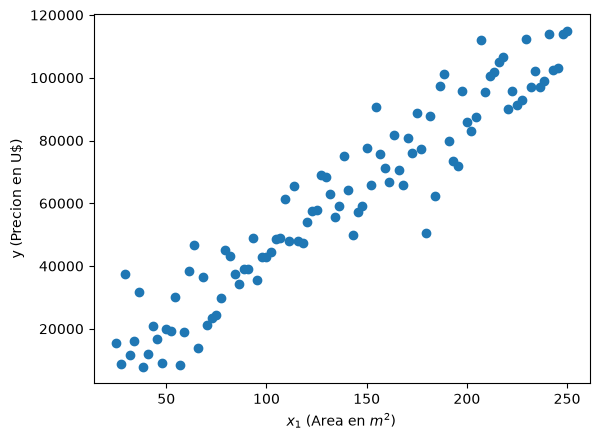

In [30]:
plt.scatter(x, y)
plt.xlabel('$x_1$ (Area en $m^2$)')
plt.ylabel('y (Precion en U$)')
plt.show()

#### Construir el modelo lineal en Keras

In [31]:
# Contenedor vacio
modelo = Sequential()

In [32]:
# comezar a llenar el modelo ('add')
modelo.add(Dense(
    units=1, 
    activation='linear', 
    input_shape=((1,))
))

c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
help(Dense)

Help on class Dense in module keras.src.layers.core.dense:

class Dense(keras.src.layers.layer.Layer)
 |  Dense(
 |      units,
 |      activation=None,
 |      use_bias=True,
 |      kernel_initializer='glorot_uniform',
 |      bias_initializer='zeros',
 |      kernel_regularizer=None,
 |      bias_regularizer=None,
 |      activity_regularizer=None,
 |      kernel_constraint=None,
 |      bias_constraint=None,
 |      lora_rank=None,
 |      lora_alpha=None,
 |      quantization_config=None,
 |      **kwargs
 |  )
 |
 |  Just your regular densely-connected NN layer.
 |
 |  `Dense` implements the operation:
 |  `output = activation(dot(input, kernel) + bias)`
 |  where `activation` is the element-wise activation function
 |  passed as the `activation` argument, `kernel` is a weights matrix
 |  created by the layer, and `bias` is a bias vector created by the layer
 |  (only applicable if `use_bias` is `True`). When this layer is
 |  followed by a `BatchNormalization` layer, it is recom

In [34]:
# informacion del modelo y = wx + b
modelo.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

#### Optimizador (Gradiente Descendiente Estocastico) y perdida

In [35]:
lr = 0.00001
optimizador = SGD(learning_rate=lr)
modelo.compile(optimizer=optimizador, loss='mse')

#### Entrenamiento y prediccion

In [36]:
n_epochs = 20
s_minibatches = 10 # probar con diferentes batch_sizes
historia = modelo.fit(x, y, epochs=n_epochs, batch_size=s_minibatches, verbose=1)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 796220672.0000  
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92798384.0000 
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734184.0000 
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 92734056.0000 
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734072.0000 
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734056.0000 
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734056.0000 
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734056.0000 
Epoch 9/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734048.0000 
Epoch 10/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734056.0000 
Epoch 11/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734048.0000 
Epoch 12/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734048.0000 
Epoch 13/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 92734016.0000 
Epoch 14/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms

#### Comportamiento del error

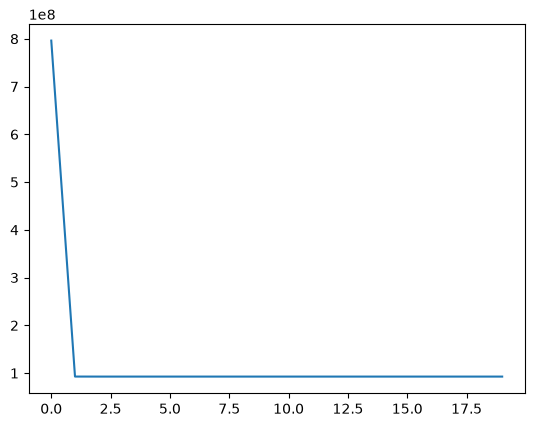

In [37]:
plt.plot(historia.history['loss']);

#### Prediccion

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


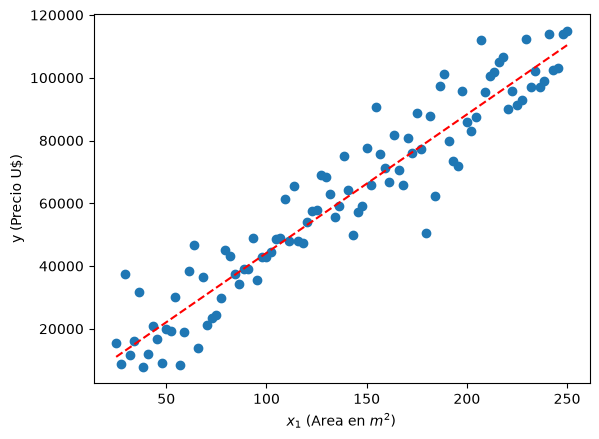

In [40]:
x_pred = np.linspace(x.min(), x.max(), x.shape[0])
y_pred = modelo.predict(x_pred)

plt.scatter(x, y)
plt.plot(x_pred, y_pred, 'r--')
plt.xlabel('$x_1$ (Area en $m^2$)')
plt.ylabel('y (Precio U$)')
plt.show()